# **Inteligencia Artificial y Aprendizaje Automático**
## **Maestría en Inteligencia Artificial Aplicada**

**Dr Luis Eduardo Falcón Morales**

**Tecnológico de Monterrey**
### **Actividad Individual: Pronósticos con Series de Tiempo**


#### **Nombre:** Miguel Labra Lorenzana
#### **Matrícula:** A01363726

Modelos para predicción de un problema de serie de tiempo:

* **1. Modelo ingenuo**
* **2. Modelo ARIMA**
* **3. Modelo Prophet**
* **4. Modelo LSTM**


NOTA: Recuerda que cada modelo puede llegar a tener una gran cantidad de hiperparámetros y tipo de ajsutes, por lo que siempre inicia con un modelo sencillo y de ahí buscar mejorar su resultado. Esto para no desgastarte desde un inicio buscando la mayor cantidad de ajustes e hiperparámetros.

# **A - Introducción**

In [1]:
# Agrega aquí todas las librerías y paquetes adicionales que requieras.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, logging
warnings.filterwarnings('ignore')

from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)   # para que los resultados de la LSTM sean repetibles


# **Ejercicio 1**

* **1a. De la página de Google-Trends generar y descargar los datos con períodos mensuales que se obtienen con el término de búsqueda "chocolate", del país "Estados Unidos", de los últimos 20 años (del 1 de marzo del 2006 al 28 de febrero del 2026) y con las opciones de "todas las categorías" y "búsqueda de web". De manera predeterminada se generan datos mensuales.**

* **1b. Cargar los datos en un DataFrame de Pandas llamado "dfp" y con los nombres"ds" y "y" para las columnas de fechas y porcentajes de interés de búsqueda, respectivamente. Las fechas ajustarlas al formato YYYY-MM-DD, con días de fin de mes. Este formato es el que se requiere para el modelo Prophet.**

* **1c. A partir del DataFrame "dfp", genera ahora el DataFrame que llamaremos "dfr" para el resto de los modelos. El formato en "dfr" requerido para el resto de los modelos debe tener la primera columna de fechas de "dfp" ahora como índice del DataFrame "dfr". Además, el índice de fechas debe tener una frecuencia mensual al final del mes.**



https://trends.google.es/trends/



In [2]:
# Ejercicios 1a y 1b.

# ************* Inlcuye aquí tu código:*****************************

# 1a. El archivo se descarga desde Google Trends (botón de descarga de la gráfica
# "Interés a lo largo del tiempo"). Normalmente se llama "multiTimeline.csv".
# Si trabajas en Colab, súbelo primero con:
#   from google.colab import files; files.upload()
archivo = 'time_series_US_20060101-0000_20261113-1233.csv'   # CSV descargado de Google Trends (cámbialo si tu archivo se llama distinto)

# Según la versión de Trends, el CSV puede traer líneas de texto antes de la tabla,
# así que buscamos el renglón donde empiezan las fechas.
with open(archivo, encoding='utf-8-sig') as f:
    lineas = f.readlines()
inicio = next(i for i, l in enumerate(lineas) if l.strip().strip('"')[:4].isdigit()) - 1   # renglón de encabezados

# 1b. DataFrame con columnas "ds" (fecha) y "y" (interés de búsqueda)
dfp = pd.read_csv(archivo, skiprows=inicio)
dfp = dfp.iloc[:, :2]
dfp.columns = ['ds', 'y']
dfp['ds'] = pd.to_datetime(dfp['ds'])
dfp['y'] = pd.to_numeric(dfp['y'].astype(str).str.replace('<1', '0'))  # por si aparece "<1"

# Si Trends entregó datos semanales, los juntamos en un solo valor por mes (promedio).
dfp['ds'] = dfp['ds'] + pd.offsets.MonthEnd(0)                         # fecha al último día del mes
dfp = dfp.groupby('ds', as_index=False)['y'].mean().round(2)
dfp = dfp[(dfp['ds'] >= '2006-03-01') & (dfp['ds'] <= '2026-02-28')].reset_index(drop=True)

# *********** Aquí termina la sección de agregar código *************

print("Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.")
print("Formato requerido por el modelo Prophet de Meta:")
print("Dimensión del DataFrame:", dfp.shape)
print(dfp.head())
print(dfp.tail())


Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.
Formato requerido por el modelo Prophet de Meta:
Dimensión del DataFrame: (240, 2)
          ds     y
0 2006-03-31  31.0
1 2006-04-30  32.0
2 2006-05-31  32.0
3 2006-06-30  28.0
4 2006-07-31  30.0
            ds      y
235 2025-10-31   65.0
236 2025-11-30   76.0
237 2025-12-31  100.0
238 2026-01-31   72.0
239 2026-02-28   79.0


In [3]:
# Ejercicio 1c.

# ************* Inlcuye aquí tu código:*****************************

# Las fechas pasan a ser el índice y se fija la frecuencia mensual (fin de mes).
dfr = dfp.set_index('ds').asfreq(pd.offsets.MonthEnd())

# *********** Aquí termina la sección de agregar código *************

print("Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.")
print("Formato requerido por los modelos restantes:")
print(dfr.shape)
print(dfr.head())
print(dfr.index)


Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.
Formato requerido por los modelos restantes:
(240, 1)
               y
ds              
2006-03-31  31.0
2006-04-30  32.0
2006-05-31  32.0
2006-06-30  28.0
2006-07-31  30.0
DatetimeIndex(['2006-03-31', '2006-04-30', '2006-05-31', '2006-06-30',
               '2006-07-31', '2006-08-31', '2006-09-30', '2006-10-31',
               '2006-11-30', '2006-12-31',
               ...
               '2025-05-31', '2025-06-30', '2025-07-31', '2025-08-31',
               '2025-09-30', '2025-10-31', '2025-11-30', '2025-12-31',
               '2026-01-31', '2026-02-28'],
              dtype='datetime64[ns]', name='ds', length=240, freq='ME')


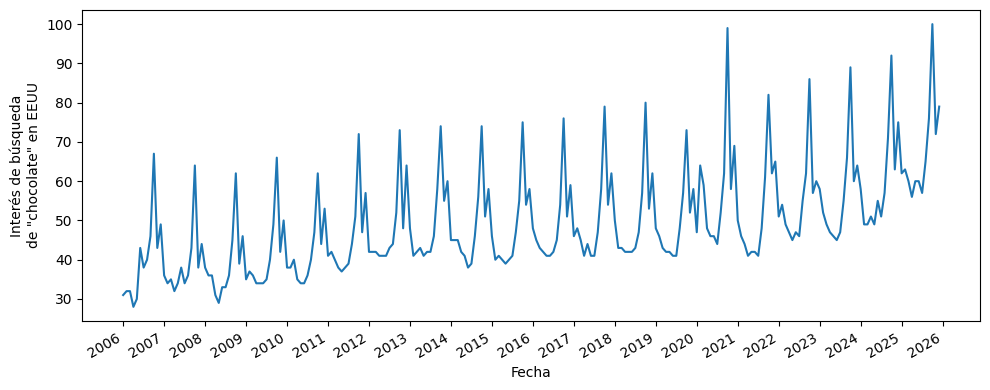

In [4]:
# Veamos el comportamiento de la serie de tiempo, en particular usemos dfp:

plt.rcParams['figure.figsize'] = (10,4)
fig, ax = plt.subplots()
ax.plot(dfp['y'])
ax.set_xlabel('Fecha')
ax.set_ylabel('Interés de búsqueda\nde \"chocolate\" en EEUU')

xticks_locs = np.arange(0, len(dfp)+12, 12) # lista: 0,12,24,36,...,240... cada 12 meses se agregará una etiqueta del año.
xticks_labels = np.arange(2006, 2027, 1)
plt.xticks(xticks_locs, xticks_labels)

fig.autofmt_xdate()
plt.tight_layout()

In [5]:
# Partición:
# Particionamos en conjunto de Prueba, Validación y Prueba de acuerdo a
# datos de una serie de tiempo y considerando el caso Prophet y el resto
# de los modelos.
# Hacemos esta diferenciación solo por fines prácticos de la actividad y
# en su momento utilizar los conjuntos respectivos en cada caso de manera
# más sencilla en la actividad.

# Para el modelo Prophet:
testP = dfp[-12:]      # El último año para prueba.
valP = dfp[-24:-12]    # El penúltimo año para validación.
trainP = dfp[:-24]     # El resto de los primeros datos para entrenamiento.

# Para el resto de los modelos:
testR = dfr[-12:]
valR = dfr[-24:-12]
trainR = dfr[:-24]


* **El objetivo de esta actividad es encontrar un modelo que pueda predecir el interés de búsqueda de la palabra "chocolate" en el navegador de Google para el próximo año. Para ello, buscaremos el modelo entrenando y validando con los conjuntos Train y Val, midiendo el desempeño con el error MAE. Con el mejor modelo encontrado obtendremos el desempeño final con el conjnuto de Prueba (Test).**

# **B - Modelo ingenuo**

# **Ejercicio - 2**

* **Iniciemos con el modelo base o ingenuo (naive/baseline).**

* **2a. En esta actividad usaremos la métrica del Error Absoluto Medio, MAE por sus siglas en inglés, "Mean Absolute Error", para monitorear el desempeño de nuestros modelos. Enuncia ventajas y desventajas de usar MAE en comparación con el error cuadrático medio MSE.**

* **2b. Encontrar e imprimir el valor del desempeño del modelo ingenuo con respecto al error MAE, llamarlo maeNaive. Utiliza el conjunto de entrenamiento trainR y como conjunto de validación valR.**

* **2c. ¿Cómo interpretas el valor MAE obtenido con el modelo ingenuo en el contexto del problema?**

* **2d. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo ingenuo, junto con los valores reales.**

**Ejercicio 2a:**

++++++++ Inicia la sección de agregar texto: +++++++++++

**Ventajas del MAE frente al MSE:**

- **Se entiende de inmediato.** El MAE está en las mismas unidades que los datos. Si el MAE es 4, el modelo se equivoca en promedio 4 puntos de interés. El MSE eleva los errores al cuadrado y queda en "puntos al cuadrado", que no tiene una lectura directa.
- **No se deja llevar por unos cuantos errores grandes.** Todos los errores pesan igual. En el MSE, un solo mes con un pico raro (por ejemplo, un febrero atípico) puede inflar la métrica y opacar que el modelo acierta bien el resto del año.

**Desventajas del MAE frente al MSE:**

- **Castiga poco los errores grandes.** Si en el negocio fallar por mucho en un mes es grave (por ejemplo, quedarse sin inventario de chocolate en San Valentín), el MSE refleja mejor ese riesgo.
- **Es menos cómodo para optimizar.** El valor absoluto tiene un "pico" en cero y no es derivable ahí, mientras que el MSE es una curva suave. Por eso muchos métodos de entrenamiento usan el MSE por defecto.

++++++++ Termina la sección de agregar texto. +++++++++++

In [6]:
# Ejercicio 2b:

# ************* Inlcuye aquí tu código:*****************************
# Incluye todas las celdas que consideres adecuadas.

# Como la serie se repite cada año (picos en las mismas fechas), usamos el
# modelo ingenuo estacional: el pronóstico de cada mes del año de validación
# es el valor que tuvo ese mismo mes un año antes (los últimos 12 meses de train).
predNaive = pd.Series(trainR['y'].values[-12:], index=valR.index)

maeNaive = mean_absolute_error(valR['y'], predNaive)

# *********** Aquí termina la sección de agregar código *************


print('\nError-modelo-Naive : MAE: %.3f' % maeNaive)



Error-modelo-Naive : MAE: 4.000


**Ejercicio 2c:**

++++++++ Inicia la sección de agregar texto: +++++++++++

Google Trends no da búsquedas absolutas: da un índice de 0 a 100, donde 100 es el mes con más interés de todo el periodo (en estos datos, diciembre de 2025). El MAE del modelo ingenuo fue de **4.00 puntos**. Eso quiere decir que, si suponemos que el año de validación (marzo 2024 a febrero 2025) se repite igual que el anterior, nos equivocamos en promedio 4 puntos por mes.

En ese año el índice anda alrededor de 60 puntos, así que el error es de cerca del 7%. Es bajo porque el interés por "chocolate" es muy regular: cada año sube en diciembre (el mes más fuerte) y en febrero (San Valentín), y baja a mitad de año.

Más que un buen o mal resultado, este número es la **vara mínima a superar**. Un modelo más elaborado solo vale la pena si logra un MAE claramente menor a 4. Si no, copiar el año pasado sería igual de útil y mucho más sencillo.

++++++++ Termina la sección de agregar texto. +++++++++++

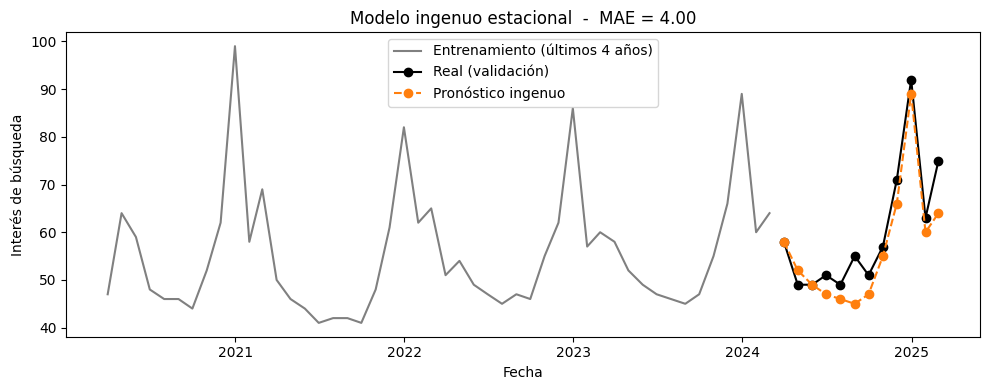

In [7]:
# Ejercicio 2d:

# ************* Inlcuye aquí tu código:*****************************

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trainR.index[-48:], trainR['y'][-48:], label='Entrenamiento (últimos 4 años)', color='gray')
ax.plot(valR.index, valR['y'], label='Real (validación)', color='black', marker='o')
ax.plot(predNaive.index, predNaive, label='Pronóstico ingenuo', color='tab:orange', marker='o', linestyle='--')
ax.set_title(f'Modelo ingenuo estacional  -  MAE = {maeNaive:.2f}')
ax.set_xlabel('Fecha'); ax.set_ylabel('Interés de búsqueda')
ax.legend(); plt.tight_layout(); plt.show()

# *********** Aquí termina la sección de agregar código *************


# **C - modelo ARIMA**

# **Ejercicio - 3**

* **3a. Aplica el modelo ARIMA con los conjuntos de entrenamiento y validación trainR y valR, usando como métrica el error absoluto medio. Llamar al error maeARIMA.**

* **3b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo ARIMA, junto con los valores reales.**

In [8]:
# Ejercicio 3a - ARIMA

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Empezamos con un ARIMA sencillo y después le agregamos la parte estacional
# (periodo de 12 meses), que es lo que más pesa en esta serie.
# Formato: (p, d, q) para la parte normal y (P, D, Q, 12) para la parte anual.
configuraciones = [
    ((1, 1, 1), (0, 0, 0, 0)),     # ARIMA simple, sin estacionalidad
    ((1, 1, 1), (1, 1, 1, 12)),    # ARIMA con estacionalidad anual (SARIMA)
    ((0, 1, 1), (0, 1, 1, 12)),    # versión más pequeña
    ((2, 1, 1), (1, 1, 1, 12)),    # versión un poco más grande
]

resultadosARIMA = []
for orden, orden_est in configuraciones:
    modelo = SARIMAX(trainR['y'], order=orden, seasonal_order=orden_est).fit(disp=False)
    pred = modelo.forecast(steps=len(valR))
    mae = mean_absolute_error(valR['y'], pred)
    resultadosARIMA.append((orden, orden_est, mae, pred))
    print(f'order={orden}, seasonal_order={orden_est}  ->  MAE = {mae:.3f}')

# Nos quedamos con la configuración de menor error
mejorOrden, mejorEstacional, maeARIMA, predARIMA = min(resultadosARIMA, key=lambda r: r[2])
print('\nMejor configuración ARIMA:', mejorOrden, mejorEstacional)


order=(1, 1, 1), seasonal_order=(0, 0, 0, 0)  ->  MAE = 10.568
order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)  ->  MAE = 4.450
order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)  ->  MAE = 4.047
order=(2, 1, 1), seasonal_order=(1, 1, 1, 12)  ->  MAE = 4.437

Mejor configuración ARIMA: (0, 1, 1) (0, 1, 1, 12)


In [9]:
print('\nError-modelo-ARIMA : MAE: %.3f' % maeARIMA)


Error-modelo-ARIMA : MAE: 4.047


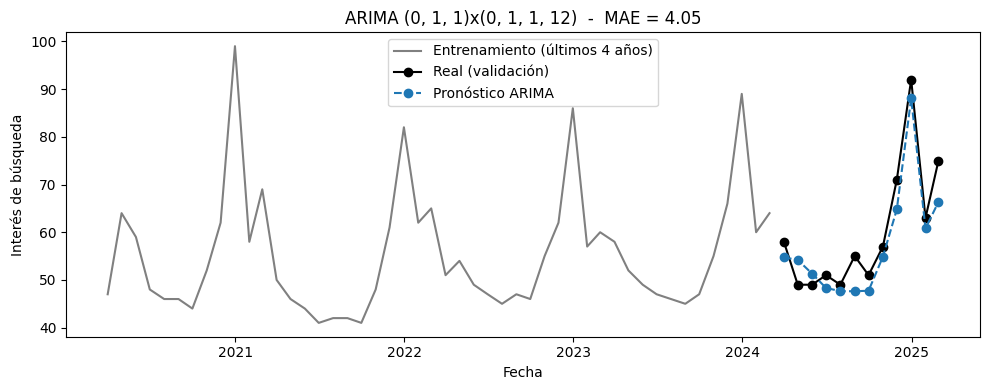

In [10]:
# Ejercicio 3b. ARIMA-gráfica:

# ************* Inlcuye aquí tu código:*****************************

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trainR.index[-48:], trainR['y'][-48:], label='Entrenamiento (últimos 4 años)', color='gray')
ax.plot(valR.index, valR['y'], label='Real (validación)', color='black', marker='o')
ax.plot(predARIMA.index, predARIMA, label='Pronóstico ARIMA', color='tab:blue', marker='o', linestyle='--')
ax.set_title(f'ARIMA {mejorOrden}x{mejorEstacional}  -  MAE = {maeARIMA:.2f}')
ax.set_xlabel('Fecha'); ax.set_ylabel('Interés de búsqueda')
ax.legend(); plt.tight_layout(); plt.show()

# *********** Aquí termina la sección de agregar código *************


# **D - modelo Prophet**

# **Ejercicio - 4**

* **4a. Aplica el modelo Prophet con los conjuntos de entrenamiento y validación trainP y valP, usando como métrica el error absoluto medio. Llamar al error maeProphet.**

* **4b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo Prophet-Facebook, junto con los valores reales.**

NOTA: Recuerda siempre iniciar con un modelo sencillo y de ahí buscar la mejor configuración.

In [11]:
# Ejercicio 4a - Prophet

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Primero Prophet con sus valores por defecto y luego dos ajustes sencillos:
# - estacionalidad multiplicativa (los picos crecen junto con el nivel de la serie)
# - tendencia más o menos flexible (changepoint_prior_scale)
configsProphet = [
    {},                                                       # por defecto
    {'seasonality_mode': 'multiplicative'},
    {'seasonality_mode': 'multiplicative', 'changepoint_prior_scale': 0.01},
    {'seasonality_mode': 'additive', 'changepoint_prior_scale': 0.5},
]

resultadosProphet = []
for cfg in configsProphet:
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, **cfg)
    m.fit(trainP)
    pronostico = m.predict(valP[['ds']])        # predecimos justo las fechas de validación
    pred = pronostico['yhat'].values
    mae = mean_absolute_error(valP['y'], pred)
    resultadosProphet.append((cfg, mae, pred))
    print(f'{cfg if cfg else "por defecto"}  ->  MAE = {mae:.3f}')

mejorCfgProphet, maeProphet, predProphet = min(resultadosProphet, key=lambda r: r[1])
print('\nMejor configuración Prophet:', mejorCfgProphet if mejorCfgProphet else 'por defecto')


por defecto  ->  MAE = 4.371
{'seasonality_mode': 'multiplicative'}  ->  MAE = 4.083
{'seasonality_mode': 'multiplicative', 'changepoint_prior_scale': 0.01}  ->  MAE = 3.651
{'seasonality_mode': 'additive', 'changepoint_prior_scale': 0.5}  ->  MAE = 4.567

Mejor configuración Prophet: {'seasonality_mode': 'multiplicative', 'changepoint_prior_scale': 0.01}


In [12]:
print('\nError-modelo-Prophet-Facebook : MAE: %.3f' % maeProphet)


Error-modelo-Prophet-Facebook : MAE: 3.651


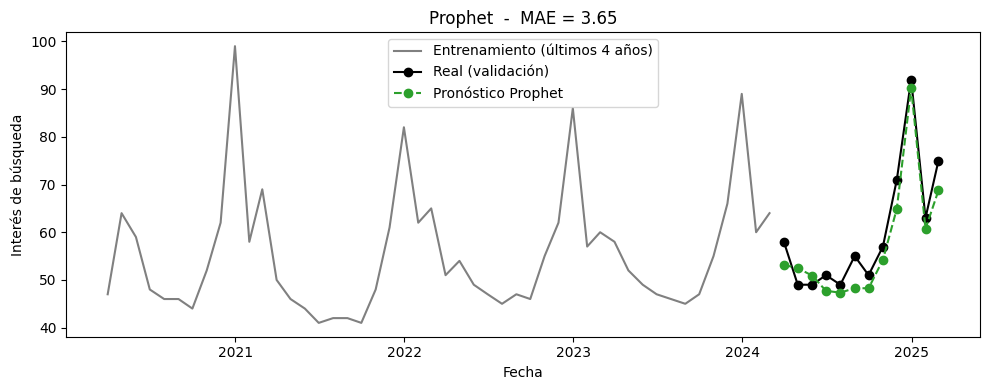

In [13]:
# Ejercicio 4b. Prophet-gráfica:

# ************* Inlcuye aquí tu código:*****************************

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trainP['ds'][-48:], trainP['y'][-48:], label='Entrenamiento (últimos 4 años)', color='gray')
ax.plot(valP['ds'], valP['y'], label='Real (validación)', color='black', marker='o')
ax.plot(valP['ds'], predProphet, label='Pronóstico Prophet', color='tab:green', marker='o', linestyle='--')
ax.set_title(f'Prophet  -  MAE = {maeProphet:.2f}')
ax.set_xlabel('Fecha'); ax.set_ylabel('Interés de búsqueda')
ax.legend(); plt.tight_layout(); plt.show()

# *********** Aquí termina la sección de agregar código *************


# **E - modelo LSTM (Deep Learning)**

# **Ejercicio - 5**

* **5a. Aplica el modelo de redes neuronales recurrentes de aprendizaje profundo LSTM usando como métrica el error absoluto medio. Llamar al error maeLSTM. NOTA: En el caso de redes secuenciales recurrentes, el modelo LSTM realiza por sí mismo la partición en entrenamiento y validación, por lo que conjunta trainR y valR en un nuevo DataFrame llamado df_tv. Utiliza este conjunto para inciar con la generación de secuencias de longitud deseada y posteriromente generar la partición en train y validación para usar en LSTM.**

* **5b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo LSTM, junto con los valores reales.**



#### **NOTA: En general, recordemos que los modelos basados en redes neuronales son afectados de manera importante cuando la escala de los datos se va incrementando. Por ello, en este caso podría ser conveniente escalar los datos de nuestra variable temporal, por ejemplo entre 0 y 1. Tomarlo en cuenta para que al final puedes realizar las predicciones en las unidades originales.**

In [14]:
# Ejercicio 5a - LSTM

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Unimos train y validación como pide la actividad
df_tv = pd.concat([trainR, valR])

# Escalamos entre 0 y 1. El escalador solo "ve" los datos de entrenamiento
# para no darle pistas al modelo sobre el año de validación.
escalador = MinMaxScaler()
escalador.fit(trainR[['y']])
serie_esc = escalador.transform(df_tv[['y']]).flatten()

# Secuencias: con los 12 meses anteriores se predice el mes siguiente
ventana = 12
def crear_secuencias(serie, ventana):
    X, Y = [], []
    for i in range(ventana, len(serie)):
        X.append(serie[i - ventana:i])
        Y.append(serie[i])
    return np.array(X)[..., np.newaxis], np.array(Y)

X, Y = crear_secuencias(serie_esc, ventana)

# Partición: las últimas 12 secuencias (las que predicen el año de validación) son validación
X_tr, Y_tr = X[:-12], Y[:-12]
X_va, Y_va = X[-12:], Y[-12:]

def construir_lstm():
    modelo = Sequential([
        Input(shape=(ventana, 1)),
        LSTM(32),
        Dense(1)
    ])
    modelo.compile(optimizer='adam', loss='mae')
    return modelo

lstm = construir_lstm()
parada = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
historia = lstm.fit(X_tr, Y_tr, validation_data=(X_va, Y_va),
                    epochs=300, batch_size=16, callbacks=[parada], verbose=0)
mejoresEpocas = int(np.argmin(historia.history['val_loss'])) + 1
print('Épocas usadas (mejor punto):', mejoresEpocas)

# Pronóstico de los 12 meses de validación "mes a mes": cada predicción se usa
# como entrada para la siguiente, igual que en los otros modelos que no ven
# los valores reales del año que están pronosticando.
def pronostico_recursivo(modelo, ultimos, pasos):
    ventana_actual = list(ultimos)
    preds = []
    for _ in range(pasos):
        x = np.array(ventana_actual[-ventana:]).reshape(1, ventana, 1)
        p = modelo.predict(x, verbose=0)[0, 0]
        preds.append(p)
        ventana_actual.append(p)
    return np.array(preds)

ultimos_train = serie_esc[len(trainR) - ventana:len(trainR)]
pred_esc = pronostico_recursivo(lstm, ultimos_train, len(valR))
predLSTM = escalador.inverse_transform(pred_esc.reshape(-1, 1)).flatten()   # regresamos a la escala original

maeLSTM = mean_absolute_error(valR['y'], predLSTM)


Épocas usadas (mejor punto): 52


In [15]:
print('\nError-modelo-LSTM : MAE: %.3f' % maeLSTM)


Error-modelo-LSTM : MAE: 3.961


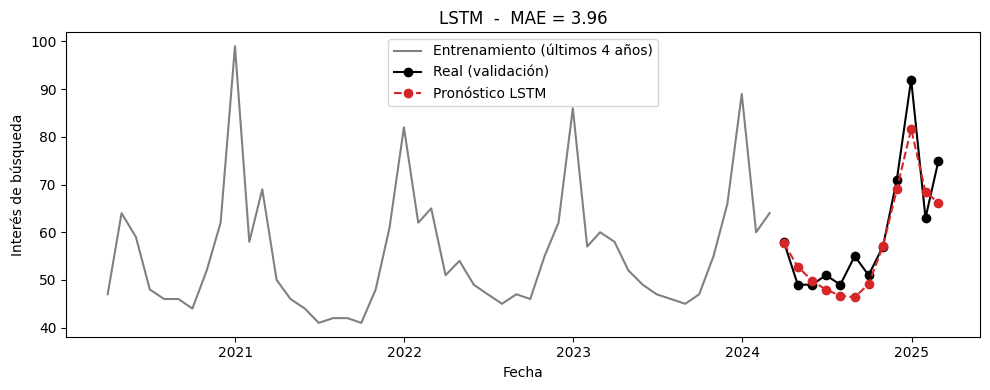

In [16]:
# Ejercicio 5b. LSTM-gráfica:

# ************* Inlcuye aquí tu código:*****************************

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trainR.index[-48:], trainR['y'][-48:], label='Entrenamiento (últimos 4 años)', color='gray')
ax.plot(valR.index, valR['y'], label='Real (validación)', color='black', marker='o')
ax.plot(valR.index, predLSTM, label='Pronóstico LSTM', color='tab:red', marker='o', linestyle='--')
ax.set_title(f'LSTM  -  MAE = {maeLSTM:.2f}')
ax.set_xlabel('Fecha'); ax.set_ylabel('Interés de búsqueda')
ax.legend(); plt.tight_layout(); plt.show()

# *********** Aquí termina la sección de agregar código *************


# **E2 - Modelo extra: SARIMAX (solo por curiosidad)**

Este modelo **no lo pide la actividad**; lo agregamos solo por curiosidad, para ver qué tal se desempeñaba.

SARIMAX es el mismo ARIMA con estacionalidad anual, pero con una **variable externa** (la "X"). Como variable externa usamos un indicador de pandemia (1 en los meses de 2020-2021 con más encierro, 0 en el resto), porque en esos meses las búsquedas de chocolate se dispararon de forma inusual (por ejemplo, abril de 2020 y diciembre de 2020).

La idea es ver si "avisarle" al modelo que esos meses fueron atípicos le ayuda a pronosticar mejor. Como no participa en la actividad, **no entra en la elección del mejor modelo del Ejercicio 6**.

In [17]:
# Modelo extra - SARIMAX con variable externa (pandemia)

# Probamos tres formas de marcar el periodo de pandemia y nos quedamos con la mejor
periodos = {
    'abr-may 2020': ('2020-04', '2020-05'),
    'abr-dic 2020': ('2020-04', '2020-12'),
    'mar 2020 - feb 2021': ('2020-03', '2021-02'),
}

def variable_pandemia(indice, inicio, fin):
    x = pd.DataFrame({'pandemia': 0.0}, index=indice)
    x.loc[inicio:fin, 'pandemia'] = 1.0
    return x

resultadosSARIMAX = []
for nombre, (ini, fin) in periodos.items():
    x_tr = variable_pandemia(trainR.index, ini, fin)
    x_va = variable_pandemia(valR.index, ini, fin)     # en validación todo es 0
    modelo = SARIMAX(trainR['y'], exog=x_tr, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    pred = modelo.forecast(steps=len(valR), exog=x_va)
    mae = mean_absolute_error(valR['y'], pred)
    resultadosSARIMAX.append((nombre, mae, pred))
    print(f'Pandemia = {nombre}  ->  MAE = {mae:.3f}')

periodoSARIMAX, maeSARIMAX, predSARIMAX = min(resultadosSARIMAX, key=lambda r: r[1])
print(f'\nMejor periodo: {periodoSARIMAX}')
print('Error-modelo-SARIMAX (extra) : MAE: %.3f' % maeSARIMAX)
print('Comparación con ARIMA sin variable externa : MAE: %.3f' % maeARIMA)

Pandemia = abr-may 2020  ->  MAE = 3.723
Pandemia = abr-dic 2020  ->  MAE = 4.449
Pandemia = mar 2020 - feb 2021  ->  MAE = 3.618

Mejor periodo: mar 2020 - feb 2021
Error-modelo-SARIMAX (extra) : MAE: 3.618
Comparación con ARIMA sin variable externa : MAE: 4.047


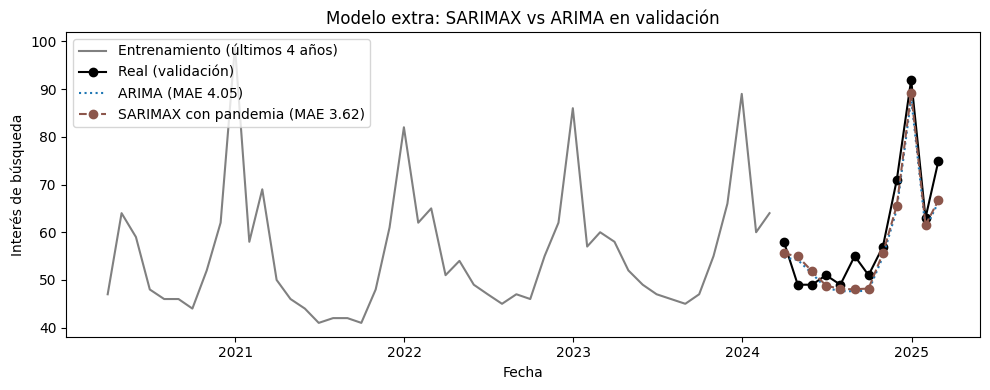

In [18]:
# Modelo extra - SARIMAX gráfica
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trainR.index[-48:], trainR['y'][-48:], label='Entrenamiento (últimos 4 años)', color='gray')
ax.plot(valR.index, valR['y'], label='Real (validación)', color='black', marker='o')
ax.plot(valR.index, predARIMA, label=f'ARIMA (MAE {maeARIMA:.2f})', color='tab:blue', linestyle=':')
ax.plot(valR.index, predSARIMAX, label=f'SARIMAX con pandemia (MAE {maeSARIMAX:.2f})', color='tab:brown', marker='o', linestyle='--')
ax.set_title('Modelo extra: SARIMAX vs ARIMA en validación')
ax.set_xlabel('Fecha'); ax.set_ylabel('Interés de búsqueda')
ax.legend(); plt.tight_layout(); plt.show()

# **F - Conjunto de Prueba y Conclusiones Finales**

# **Ejercicio - 6**

* **Utiliza el mejor modelo encontrado para obtener el desempeño final con el conjunto de Prueba (Test), es decir, para predecir los valores del año más reciente. Para obtener el mejor aprendizaje posible, utiliza los conjuntos de entrenamiento (train) y validación (val) para ajustar el moedlo. Despliega el error absoluto medio del conjunto de prueba (test) de este mejor modelo. Llamarlo maeMejor.**

MAE en validación:
Prophet    3.651
LSTM       3.961
Ingenuo    4.000
ARIMA      4.047
dtype: float64

Mejor modelo: Prophet


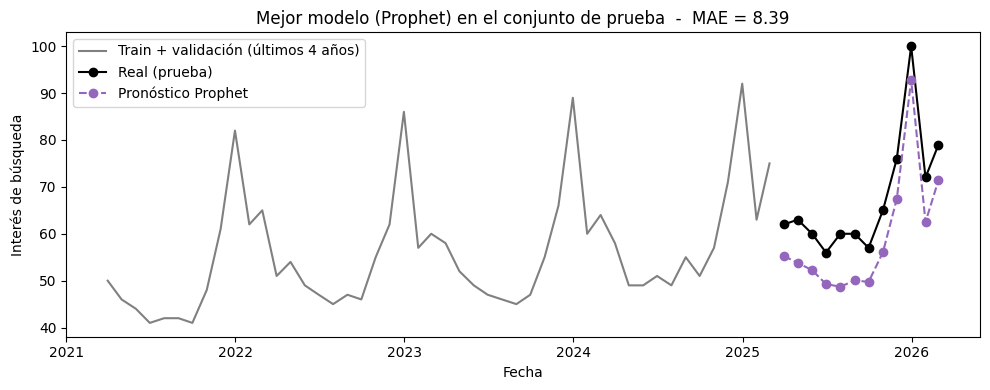

In [19]:
# Ejercicio 6 - mejor modelo

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Resumen de validación y elección del mejor modelo (menor MAE)
resumen = pd.Series({'Ingenuo': maeNaive, 'ARIMA': maeARIMA,
                     'Prophet': maeProphet, 'LSTM': maeLSTM}).sort_values()
print('MAE en validación:')
print(resumen.round(3))
mejorModelo = resumen.index[0]
print('\nMejor modelo:', mejorModelo)

# Reentrenamos el mejor modelo con train + validación y pronosticamos el año de prueba
trainValR = pd.concat([trainR, valR])
trainValP = pd.concat([trainP, valP])

if mejorModelo == 'Ingenuo':
    predTest = trainValR['y'].values[-12:]

elif mejorModelo == 'ARIMA':
    modelo = SARIMAX(trainValR['y'], order=mejorOrden, seasonal_order=mejorEstacional).fit(disp=False)
    predTest = modelo.forecast(steps=len(testR)).values

elif mejorModelo == 'Prophet':
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, **mejorCfgProphet)
    m.fit(trainValP)
    predTest = m.predict(testP[['ds']])['yhat'].values

else:  # LSTM
    tf.keras.utils.set_random_seed(42)
    escalador = MinMaxScaler().fit(trainValR[['y']])
    serie_tv = escalador.transform(trainValR[['y']]).flatten()
    X_all, Y_all = crear_secuencias(serie_tv, ventana)
    lstm_final = construir_lstm()
    lstm_final.fit(X_all, Y_all, epochs=mejoresEpocas, batch_size=16, verbose=0)
    pred_esc = pronostico_recursivo(lstm_final, serie_tv[-ventana:], len(testR))
    predTest = escalador.inverse_transform(pred_esc.reshape(-1, 1)).flatten()

maeMejor = mean_absolute_error(testR['y'], predTest)

# Gráfica del pronóstico final contra el año de prueba
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trainValR.index[-48:], trainValR['y'][-48:], label='Train + validación (últimos 4 años)', color='gray')
ax.plot(testR.index, testR['y'], label='Real (prueba)', color='black', marker='o')
ax.plot(testR.index, predTest, label=f'Pronóstico {mejorModelo}', color='tab:purple', marker='o', linestyle='--')
ax.set_title(f'Mejor modelo ({mejorModelo}) en el conjunto de prueba  -  MAE = {maeMejor:.2f}')
ax.set_xlabel('Fecha'); ax.set_ylabel('Interés de búsqueda')
ax.legend(); plt.tight_layout(); plt.show()


In [20]:
print('\nError-del-mejor-modelo-Test : MAE: %.3f' % maeMejor)


Error-del-mejor-modelo-Test : MAE: 8.392


**Curiosidad:** ¿cómo le habría ido al SARIMAX en el año de prueba? Solo como referencia, no cambia la elección del mejor modelo del Ejercicio 6.

         MAE validación       Tipo  MAE prueba
SARIMAX           3.618      Extra       4.122
Prophet           3.651  Actividad       8.392
LSTM              3.961  Actividad           -
Ingenuo           4.000  Actividad           -
ARIMA             4.047  Actividad           -


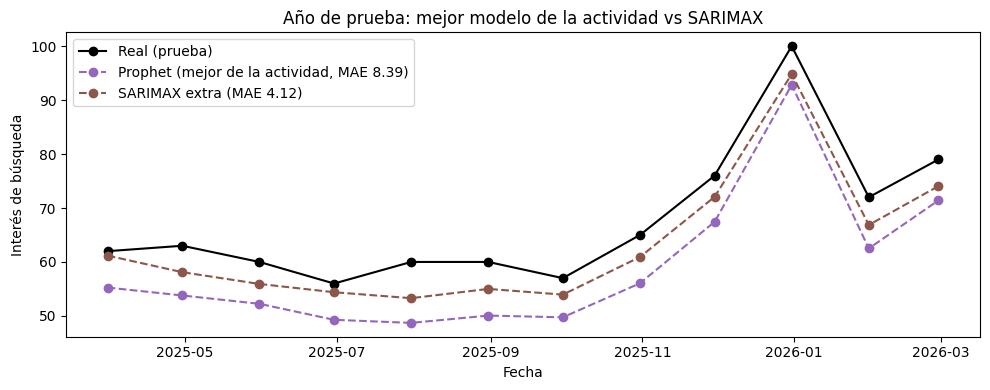

In [21]:
# SARIMAX (extra) en prueba
ini, fin = periodos[periodoSARIMAX]
x_tv = variable_pandemia(trainValR.index, ini, fin)
x_te = variable_pandemia(testR.index, ini, fin)
modelo = SARIMAX(trainValR['y'], exog=x_tv, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
predTestSARIMAX = modelo.forecast(steps=len(testR), exog=x_te)
maeSARIMAXTest = mean_absolute_error(testR['y'], predTestSARIMAX)

tabla = pd.DataFrame({
    'MAE validación': [maeNaive, maeARIMA, maeProphet, maeLSTM, maeSARIMAX],
    'Tipo': ['Actividad'] * 4 + ['Extra'],
}, index=['Ingenuo', 'ARIMA', 'Prophet', 'LSTM', 'SARIMAX'])
tabla['MAE prueba'] = np.nan
tabla.loc[mejorModelo, 'MAE prueba'] = maeMejor
tabla.loc['SARIMAX', 'MAE prueba'] = maeSARIMAXTest
print(tabla.sort_values('MAE validación').round(3).to_string(na_rep='-'))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(testR.index, testR['y'], label='Real (prueba)', color='black', marker='o')
ax.plot(testR.index, predTest, label=f'{mejorModelo} (mejor de la actividad, MAE {maeMejor:.2f})', color='tab:purple', marker='o', linestyle='--')
ax.plot(testR.index, predTestSARIMAX, label=f'SARIMAX extra (MAE {maeSARIMAXTest:.2f})', color='tab:brown', marker='o', linestyle='--')
ax.set_title('Año de prueba: mejor modelo de la actividad vs SARIMAX')
ax.set_xlabel('Fecha'); ax.set_ylabel('Interés de búsqueda')
ax.legend(); plt.tight_layout(); plt.show()

# **Ejercicio - 7**

* **Incluye tus comentarios y conclusiones finales de la actividad.**


++++++++ Inicia la sección de agregar texto: +++++++++++

**Resultados en validación (MAE):** Prophet 3.65 · LSTM 3.96 · Ingenuo 4.00 · ARIMA 4.05.
**Modelo extra:** SARIMAX 3.62.
**Prueba:** Prophet (mejor de la actividad) 8.39 · SARIMAX (extra, solo como referencia) 4.12.

- **La serie es muy estacional.** El interés por "chocolate" en EE. UU. tiene el mismo ciclo cada año: el pico más alto en diciembre, otro en febrero por San Valentín y meses más bajos a mitad de año. Por eso el modelo ingenuo, que solo copia el año anterior, ya da un error bajo (4.00). En cambio, el ARIMA sin parte estacional se fue a un MAE de 10.6, porque no "sabe" que diciembre siempre sube.

- **Los modelos quedaron muy parejos en validación.** Prophet ganó (3.65) con una tendencia poco flexible y estacionalidad multiplicativa. La LSTM y el ingenuo quedaron casi empatados, y el ARIMA estacional no logró superar al ingenuo. En una serie tan regular, los modelos complejos mejoran poco sobre la línea base, y la diferencia entre ellos es de menos de medio punto.

- **En prueba, Prophet falló mucho más (8.39).** Al revisar mes por mes, Prophet acertó la forma del año, pero se quedó corto en todos los meses por unos 7 a 11 puntos. En 2025 el interés promedio brincó de ~60 a ~67, y diciembre de 2025 llegó al máximo histórico (100). La tendencia "rígida" que le ayudó en validación es justo la que le impidió reaccionar a ese salto. Es un buen ejemplo de que ganar en validación por poco no garantiza ganar en prueba.

- **¿Por qué agregamos SARIMAX?** Además de los cuatro modelos de la actividad, añadimos únicamente SARIMAX, porque creímos que sería una buena opción para obtener resultados relevantes, y descubrimos que sí. La diferencia esencial de SARIMAX frente al ARIMA es que le da peso a **factores externos** a la serie. En nuestro caso, el factor externo fue un indicador de los meses de pandemia (mar 2020 a feb 2021), cuando las búsquedas de chocolate se dispararon por razones que no tienen que ver con el ciclo normal del año. Con solo ese dato adicional, el error bajó de 4.05 (ARIMA) a 3.62 en validación, el mejor de todos. En prueba obtuvo 4.12, la mitad del error de Prophet. Como no forma parte de la actividad no lo usamos como mejor modelo oficial, pero muestra lo mucho que pesan los factores externos en este tipo de series.

- **Conclusión final.** Entre los modelos de la actividad, el mejor en validación fue Prophet, pero en prueba falló por su tendencia rígida. El modelo que mejor se comportó en ambos conjuntos fue el SARIMAX con la variable de pandemia. La lección es que entender la serie (su estacionalidad y sus eventos raros) ayudó más que usar un modelo más complejo.

- **Tener una línea base fue clave.** Sin el modelo ingenuo no habría forma de saber si un MAE de 4 es bueno o malo. Compararlo mostró qué tanto aporta realmente cada modelo.

- **Limitaciones.** Google Trends es un índice relativo y se recalcula en cada descarga, así que los valores pueden cambiar un poco. Además se validó con un solo año. Usar varios cortes en el tiempo daría una comparación más confiable y probablemente habría detectado que Prophet se adapta lento a cambios de nivel.

Declaración de uso de IA: Claude (Anthropic), aclarar conceptos, mejorar la redacción y depurar errores en Google ColaB, con ajustes en el flujo del codigo.

++++++++ Termina la sección de agregar texto. +++++++++++

# **++ Fin de la Actividad de la Semana - Pronósticos y Series de Tiempo ++**